In [1]:
!git clone -q https://github.com/esa/SpOC2.git
%cd "/kaggle/working/SpOC2/Morphing Rovers"
!mkdir -p data/spoc2/morphing && cp -r data/Maps data/coordinates.txt data/example_rover.npy data/spoc2/morphing/
!sed -i "77s/.*/HEIGHTMAP_NAMES = ['Map1.jpg', 'Map2.jpg', 'Map3.jpg', 'Map4.jpg', 'Map5.jpg', 'Map6.jpg']/" morphing_udp.py
!sed -i '683s/, angle,/, float(angle),/' morphing_udp.py

/kaggle/working/SpOC2/Morphing Rovers


In [2]:
!wget -q -O hill_climbing_best.npy https://raw.githubusercontent.com/vesabraina/VesaBraina-MorphingRovers/main/checkpoints/hill_climbing_best.npy
import numpy as np, time
import matplotlib.pyplot as plt
from morphing_udp import morphing_rover_UDP

udp = morphing_rover_UDP()
lb, ub = map(np.array, udp.get_bounds())
x0 = np.load("hill_climbing_best.npy")
nota0 = udp.fitness(x0)[0]
print("Nota e checkpoint-it:", round(nota0, 3))

Nota e checkpoint-it: 5.421


In [3]:
rng = np.random.default_rng(1)

def ndrysho_pak(x, sa_numra=100, sa_shume=1.0):
    y = x.copy()
    idx = rng.choice(len(x) - 7, size=sa_numra, replace=False)
    y[idx] += rng.normal(0, sa_shume, sa_numra)
    return np.clip(y, lb, ub)

def kryqezo(a, b):
    maska = rng.random(len(a)) < 0.5
    femija = np.where(maska, a, b)
    femija[-7:] = a[-7:]
    return femija

def zgjidh_prind(pop, notat):
    i, j = rng.choice(len(pop), 2, replace=False)
    return pop[i] if notat[i] < notat[j] else pop[j]

In [4]:
P = 8
pop = [x0] + [ndrysho_pak(x0) for _ in range(P - 1)]
notat = [nota0]
for k, p in enumerate(pop[1:]):
    notat.append(udp.fitness(p)[0])
    print(f"Roveri {k+2}: nota {notat[-1]:.3f}")

Roveri 2: nota 7.080
Roveri 3: nota 5.442
Roveri 4: nota 8.396
Roveri 5: nota 9.800
Roveri 6: nota 6.433
Roveri 7: nota 6.554
Roveri 8: nota 4.739


In [5]:
G = 5
historia = [min(notat)]
t = time.time()
for g in range(G):
    rendi = np.argsort(notat)
    pop_re = [pop[rendi[0]], pop[rendi[1]]]
    notat_re = [notat[rendi[0]], notat[rendi[1]]]
    while len(pop_re) < P:
        femija = ndrysho_pak(kryqezo(zgjidh_prind(pop, notat), zgjidh_prind(pop, notat)))
        pop_re.append(femija)
        notat_re.append(udp.fitness(femija)[0])
    pop, notat = pop_re, notat_re
    i = int(np.argmin(notat))
    historia.append(notat[i])
    np.save("ga_best.npy", pop[i])
    print(f"Gjenerata {g+1}: më e mira {notat[i]:.3f}, mesatarja {np.mean(notat):.3f}")
print("Koha:", round(time.time() - t), "sekonda")

Gjenerata 1: më e mira 4.739, mesatarja 7.397
Gjenerata 2: më e mira 4.739, mesatarja 6.925
Gjenerata 3: më e mira 4.739, mesatarja 6.785
Gjenerata 4: më e mira 4.739, mesatarja 6.738
Gjenerata 5: më e mira 4.739, mesatarja 6.845
Koha: 804 sekonda


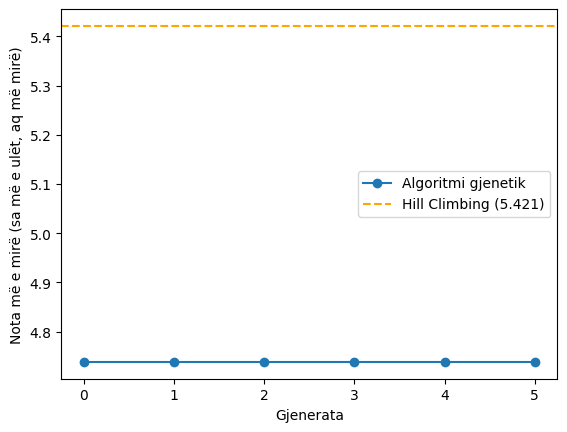

In [6]:
plt.plot(range(G + 1), historia, marker="o", label="Algoritmi gjenetik")
plt.axhline(5.421, color="orange", linestyle="--", label="Hill Climbing (5.421)")
plt.xlabel("Gjenerata")
plt.ylabel("Nota më e mirë (sa më e ulët, aq më mirë)")
plt.legend()
plt.savefig("algoritmi_gjenetik.png", dpi=120, bbox_inches="tight")
plt.show()